# Lab 3 - CRISP-DM Data Preparation
## Data cleaning, transformation and feature engineering

> How to prepare data for machine learning algorithms and create new, informative features

## Learning objectives

* Understand the main steps involved in preparing data for machine learning algorithms
* Create Python functions to automate steps of the data cleaning process
* Gain an introduction to matplotlib's object-oriented interface to combine plots on the same figure

## References

This lesson draws heavily on the following textbook chapter:

* Chapter 2 of _Hands-On Machine Learning with Scikit-Learn and TensorFlow_ by Aurèlien Geron

You may also find the following blog posts useful:

* [Machine Learning with Kaggle: Feature Engineering
](https://www.datacamp.com/community/tutorials/feature-engineering-kaggle)
* Sections 2 and 3 of [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning) on Kaggle Learn
* [Effectively Using Matplotlib](https://pbpython.com/effective-matplotlib.html) by C. Moffitt

## What is data cleaning?

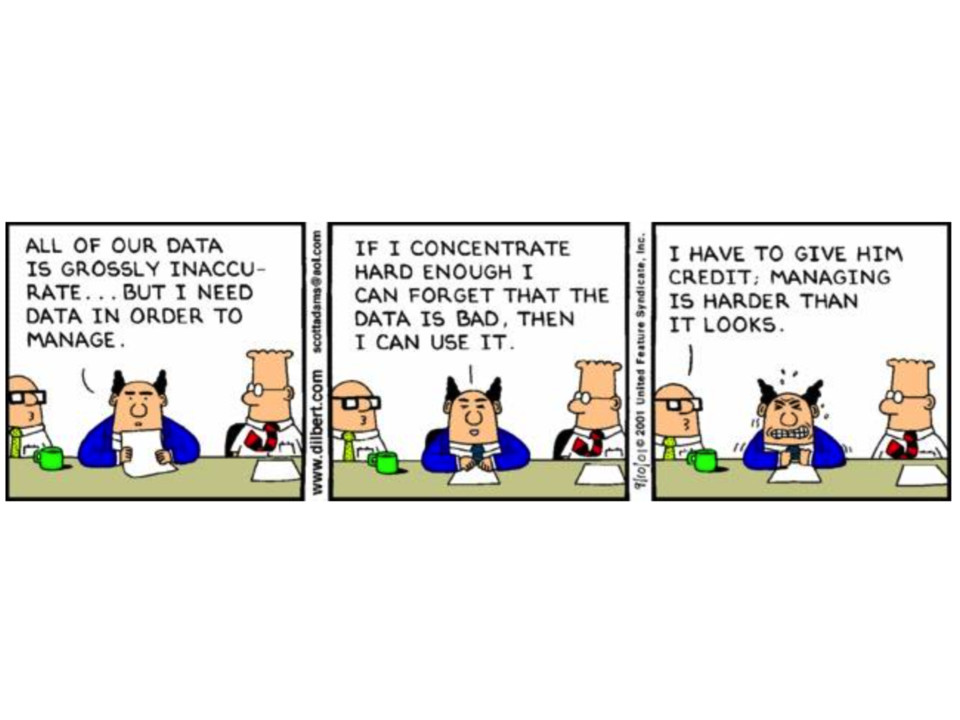
When you receive a new dataset at the beginning of a project, the first task usually involves some form of data cleaning.

To solve the task at hand, you might need data from multiple sources which you need to combine into one unified table. However, this is usually a tricky task; the different data sources might have different naming conventions, some of them might be human-generated, while others are automatic system reports. A list of things you usually have to go through are the following:

* Merge multiple sources into one table
* Remove duplicate entries
* Clean corrupted entries
* Handle missing data

In lesson 2, we examined how to merge the table of housing data with their addresses; in this lesson we will focus on the remainign three steps.

Although building algorithms that are able to classify data or estimate outcomes is arguably the most interesting part of data science, data cleaning is the one that takes up most of the time. According to a study by [CrowdFlower](https://www.forbes.com/sites/gilpress/2016/03/23/data-preparation-most-time-consuming-least-enjoyable-data-science-task-survey-says/#67beee196f63), data scientists spend about 60-80% of their time preparing datasets for machine learning algorithms.

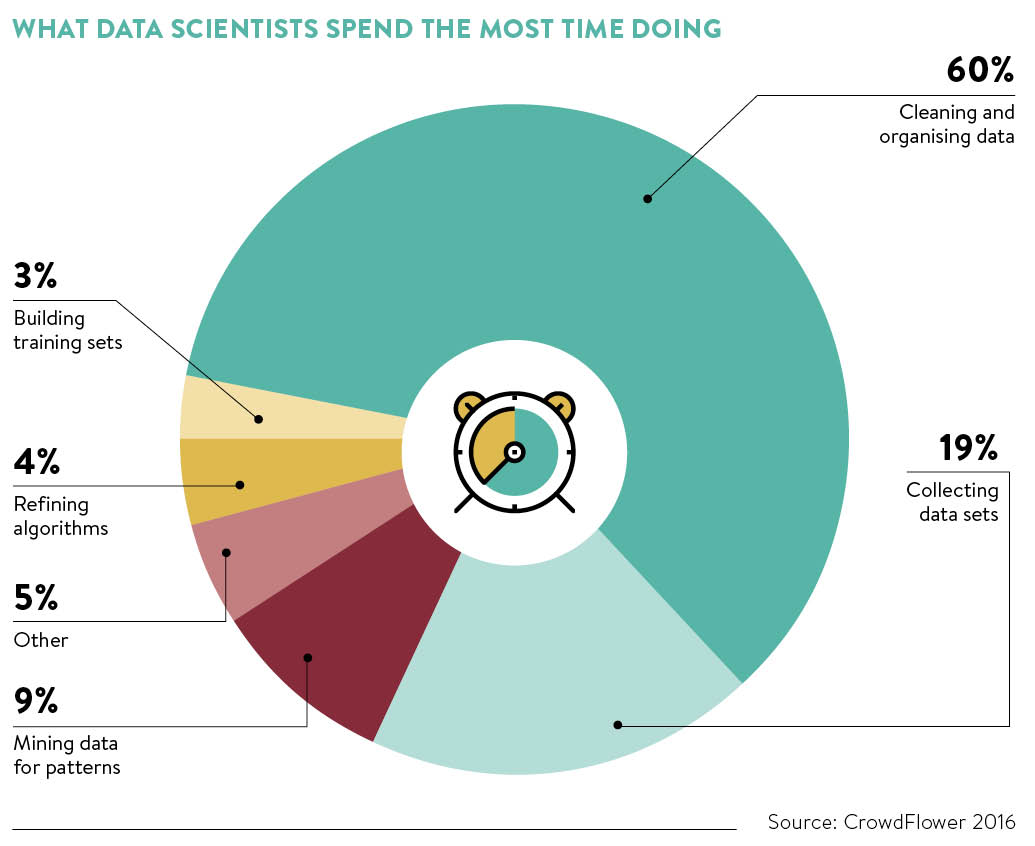

## The data

In this lesson we will analyse the unified table of housing data and their addresses that we created in lesson 2:

* `housing_merged.csv`

## Import libraries

As in previous lessons, we will be making use of the pandas and seaborn libraries.

In [ ]:
# data wrangling
import pandas as pd
import numpy as np
from pathlib import Path

# data viz
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# these commands define the color scheme
sns.set(color_codes=True)
sns.set_palette(sns.color_palette('muted'))

## Load the data

As usual, we can download our datasets using our helper function `get_datasets`:

In [ ]:
DATA = Path('../content') # you may need to change this location depending on where you uploaed your files to
!ls {DATA}

housing_data = pd.read_csv(DATA/'housing_merged.csv');
housing_data.head()



housing_merged.csv  sample_data


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2005,Tunnel Road,Oakland,94611.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,6886,Chabot Road,Oakland,94618.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,6365,Florio Street,Oakland,94618.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6365,Florio Street,Oakland,94618.0


We also make use of the `pathlib` library to handle our filepaths:

In [ ]:
housing_data = pd.read_csv(DATA/'housing_merged.csv');
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2005,Tunnel Road,Oakland,94611.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,6886,Chabot Road,Oakland,94618.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,6365,Florio Street,Oakland,94618.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6365,Florio Street,Oakland,94618.0


## Inspect structure before changing data
This is the handover from Data Understanding to Data Preparation.

In [ ]:
print("Shape:", housing_data.shape)
print("Columns:", housing_data.columns.tolist())
display(housing_data.dtypes.to_frame("dtype"))
housing_data.info()
display(housing_data.describe(include="all").T)

Shape: (20640, 14)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity', 'street_number', 'street_name', 'city', 'postal_code']


,dtype
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
 10  street_number       19008 non-null  object 
 11  street_name         20091 non-null  object 
 12  city                20452 non-null  object 
 13  postal_code         20454 non-null  float64
dtypes: float64(10), object(4)
memory usage: 2.2+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Feature engineering

Before we prepare the data for training machine learning models, it is useful to experiment with creating new _**features**_ (i.e. columns) that may provide more information than the raw data alone. For example the column `total_rooms` refers to the total number of rooms in a housing district, and thus it is more useful to know the number of rooms per household. In pandas, we can create this new column as follows:

In [ ]:
housing_data['rooms_per_household'] = housing_data['total_rooms'] / housing_data['households']
# check we have added the column
housing_data.head(1)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code,rooms_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0,6.984127


---

#### Exercise #1

* Create a new feature called `bedrooms_per_household` from the `total_bedrooms` and `households` features
* Create a new feature called `bedrooms_per_room` from the `total_bedrooms` and `total_rooms` features
* Create a new feature called `population_per_household` from the `population` and `households` features
* Calculate the correlation matrix (similar to lab 1) - what can you conclude about the correlation of the new features with the median house value?

---

In [ ]:
# Write your code here

# 1. Create a new feature called `bedrooms_per_household` from the `total_bedrooms` and `households` features
housing_data['bedrooms_per_household'] = housing_data['total_bedrooms'] / housing_data['households']

# 2. Create a new feature called `bedrooms_per_room` from the `total_bedrooms` and `total_rooms` features
housing_data['bedrooms_per_room'] = housing_data['total_bedrooms'] / housing_data['total_rooms']

#3. Create a new feature called `population_per_household` from the `population` and `households` features
housing_data['population_per_household'] = housing_data['population'] / housing_data['households']

display(housing_data.head())

#4. Calculate the correlation matrix (similar to lab 1) - what can you conclude about the correlation of the new features with the median house value?
correlation_matrix = housing_data.select_dtypes(include=np.number).corr()
correlation_matrix['median_house_value'].sort_values(ascending=False)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,street_number,street_name,city,postal_code,rooms_per_household,bedrooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,3130,Grizzly Peak Boulevard,Berkeley,94705.0,6.984127,1.023810,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,2005,Tunnel Road,Oakland,94611.0,6.238137,0.971880,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,6886,Chabot Road,Oakland,94618.0,8.288136,1.073446,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,6365,Florio Street,Oakland,94618.0,5.817352,1.073059,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6365,Florio Street,Oakland,94618.0,6.281853,1.081081,0.172096,2.181467


,median_house_value
median_house_value,1.000000
median_income,0.688075
rooms_per_household,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population_per_household,-0.023737
population,-0.024650
longitude,-0.045967


## Remove the housing price cap

Recall from lesson 1 that the quantity we wish to predict (median house value) has a cap around $500,000:

/tmp/ipykernel_2317/282892120.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(housing_data["median_house_value"], kde=False, ax=ax0)


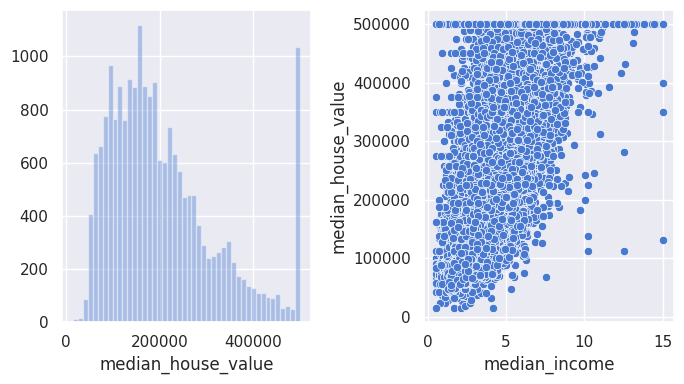

In [ ]:
# use plt.subplots() to create multiple plots
fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))
# put one plot on axis ax0
sns.distplot(housing_data["median_house_value"], kde=False, ax=ax0)
# put second plot on axis ax1
sns.scatterplot(x="median_income", y="median_house_value", data=housing_data, ax=ax1)
# tight_layout() fixes spacing between plots
fig.tight_layout()

> Tip: Up until now, we have always made individual plots to visualise the data. The example above shows how matplotlib can be used to show two plots on the same figure! See the _Effectively Using Matplotlib_ link in the references for more information.

The presence of this cap is potentially problematic since our machine learning algorithms may learn that the housing prices never go beyond that limit. Let's assume that we want to predict housing prices above $500,000, in which case we should remove these districts from the dataset.

---

#### Exercise #2

* Store the number of rows in `housing_data` in a variable called `n_rows_raw`
* Use the `DataFrame.loc[]` method to remove all rows where `median_house_value` is greater than or equal to $500,000
* Calculate the fraction of data that has been removed by this filter.
* Create new histogram and scatter plots to make sure you have removed the capped values correctly.

---

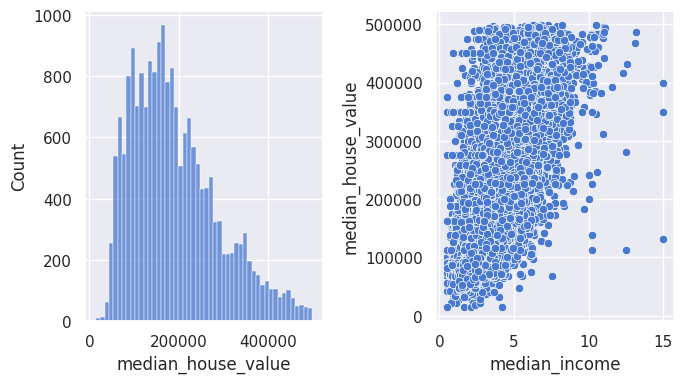

In [ ]:
# Write you code here

# 1. Store the number of rows in `housing_data` in a variable called `n_rows_raw`
n_rows_raw = len(housing_data)

# 2. Use the `DataFrame.loc[]` method to remove all rows where `median_house_value` is greater than or equal to $500,000
housing_data = housing_data.copy().loc[housing_data['median_house_value'] < 500000]

# 3. Calculate the fraction of data that has been removed by this filter.
1.0 - len(housing_data) / n_rows_raw

# 4. Create new histogram and scatter plots to make sure you have removed the capped values correctly.
fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(7, 4))
sns.histplot(housing_data["median_house_value"], kde=False, ax=ax0)
sns.scatterplot(x="median_income", y="median_house_value", data=housing_data, ax=ax1)
fig.tight_layout()




## Convert strings to categories

If we inspect the data types associated with our housing `pandas.DataFrame`

In [ ]:
housing_data.dtypes

,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,object


we see that in addition to numerical features, we have features of `object` data type, which pandas denotes with the string `O`:

In [ ]:
housing_data['ocean_proximity'].dtype

dtype('O')

In [ ]:
# compare against numerical column
housing_data['median_house_value'].dtype

dtype('float64')

pandas has a handy set of functions to test the data type of each column. For example, to check whether a column is of object or numeric type we can import the following functions

In [ ]:
from pandas.api.types import is_object_dtype, is_numeric_dtype

and then test them against some columns:

In [ ]:
is_object_dtype(housing_data['ocean_proximity'])

True

In [ ]:
is_numeric_dtype(housing_data['ocean_proximity'])

False

In [ ]:
is_numeric_dtype(housing_data['median_house_value'])

True

In this case, we know these columns are _strings_ and some step is needed to convert them to numerical form because most machine learning algorithms are best suited for doing computations on arrays of numbers, not strings.

pandas has a special `Categorical` type for holding data that uses the integer-based categorical representation or **_encoding_**. For example `housing_data['ocean_proximity']` is a `pandas.Series` of Python string objects `['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']`. We can convert a `pandas.DataFrame` column to categorical as follows:

In [ ]:
housing_data['ocean_proximity'] = housing_data['ocean_proximity'].astype('category')

The resulting `Categorical` object has `categories` and `codes` attributes that can be accessed as follows:

In [ ]:
housing_data['ocean_proximity'].cat.categories

Index(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'], dtype='object')

In [ ]:
housing_data['ocean_proximity'].cat.codes

,0
0,3
1,3
2,3
3,3
4,3
...,...
20635,1
20636,1
20637,1
20638,1


> Note: pandas will display `Categorical` features as text and treat them internally as numerical.

Sometimes we may want to reorder by hand the categorical variables. For example, with our `ocean_proximity` feature, it makes more sense to order the categories by distance to the ocean:

In [ ]:
housing_data["ocean_proximity"] = housing_data["ocean_proximity"].cat.set_categories(
    ["INLAND", "<1H OCEAN", "NEAR BAY", "NEAR OCEAN", "ISLAND"], ordered=True
)

> Tip: Instead of doing each data cleaning step manually, it is a good idea to write functions that automate the process. The main benefits from doing so is that you will be able to reproduce your results at a later date and can reuse the functions in future projects. The exercise below is desiged to help you create your first data cleaning function!

---

#### Exercise #3

* Create a function called `convert_strings_to_categories` that takes a `pandas.DataFrame` as an argument and converts all columns of `object` type into `Categorical`. Note that the operation can be done in-place and thus your function should not return any objects. You may find the commands `DataFrame.columns` and `is_numeric_dtype` are useful.
* Check that the transformed `housing_data` has the expected data types.

---

In [ ]:
from pandas.api.types import is_object_dtype, is_numeric_dtype

def convert_strings_to_categories(df):
    for col in df.columns:
        if is_object_dtype(df[col]):
            df[col] = df[col].astype('category')

In [ ]:
convert_strings_to_categories(housing_data)
housing_data.dtypes

,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,category


## Dealing with missing values

In general, machine learning algorithms will fail to work with missing data, and in general you have three options to handle them:

* Get rid of the corresponding rows
* Get rid of the whole feature or column
* Replace the missing values with some value like zero or the mean, median of the column.

A quick way to check if there's any missing data is to run the pandas `DataFrame.info()` method:

In [ ]:
housing_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   longitude            20640 non-null  float64
 1   latitude             20640 non-null  float64
 2   housing_median_age   20640 non-null  float64
 3   total_rooms          20640 non-null  float64
 4   total_bedrooms       20433 non-null  float64
 5   population           20640 non-null  float64
 6   households           20640 non-null  float64
 7   median_income        20640 non-null  float64
 8   median_house_value   20640 non-null  float64
 9   ocean_proximity      20640 non-null  object 
 10  street_number        19008 non-null  object 
 11  street_name          20091 non-null  object 
 12  city                 20452 non-null  object 
 13  postal_code          20454 non-null  float64
 14  rooms_per_household  20640 non-null  float64
dtypes: float64(11), object(4)
memory usa

Since `housing_data` has 20,640 rows we see that the following columns are missing values:

* `total_bedrooms`
* `street_number`
* `street_name`
* `city`
* `postal_code`
* `bedrooms_per_household`
* `bedrooms_per_room`

An alternative way to verify this is to apply the `DataFrame.isnull()` method and calculate the sum of missing values in `housing_data`:

In [ ]:
housing_data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


---

#### Exercise #4

It is often more informative to know the fraction or percentage of missing values in a `pandas.DataFrame`.

* Calculate the _fraction_ of missing values in `housing_data` and sort them in descending order.
* Use seaborn to create a bar plot that shows the fraction of missing data that you calculated above.

---

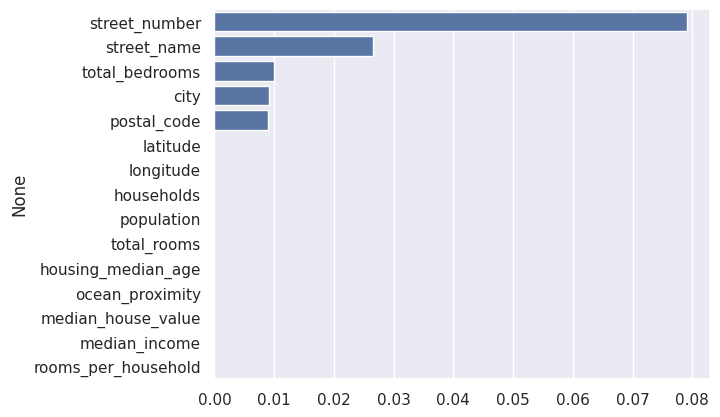

In [ ]:
missing_values = (housing_data.isnull().sum() / len(housing_data)).sort_values(ascending=False)
sns.barplot(x=missing_values.values, y=missing_values.index, color='b');

### Getting rid of rows

Let's look at our first option to handle missing data: getting rid of rows. One candidate for this is the `city` column since dropping the 188 rows amounts to less than 1% of the total dataset. To achieve this we can use the `DataFrame.dropna()` method as follows:

In [ ]:
housing_data.dropna(subset=['city'], inplace=True)
# check city has no missing values
housing_data['city'].isnull().sum()

np.int64(0)

---

#### Exercise #5

* Use the same technique as above to remove the rows whether the `postal_code` values are missing
* Use the `Series.astype()` method to convert the `postal_code` to `int` type

---

In [ ]:


# Use the same technique as above to remove the rows whether the postal_code values are missing
housing_data.dropna(subset=['postal_code'], inplace=True)

# check postal_code has no missing values
print(housing_data['postal_code'].isnull().sum())

#Use the Series.astype() method to convert the postal_code to int type
housing_data['postal_code'] = housing_data['postal_code'].astype(int)

0


### Getting rid of whole features

We still have missing values for the categorical features `street_number` and `street_name`. For such data one simple approach is to replace the missing values with the _most frequent entry_. However, for these specific attributes it does not make much sense to replace e.g. the missing street names with the most common ones in some other city.

To that end, we will drop the `street_number` and `street_name` columns.

---

#### Exercise #6

Drop the `street_number`, `street_name` and `postal_code` columns from `housing_data`

---

In [ ]:


# Drop the street_number, street_name and postal_code columns from housing_data
housing_data.drop(columns= ['street_number','street_name','postal_code'], axis=1, inplace=True)
housing_data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
city,0


### Fill missing values

For the numerical columns, let's replace the missing values by the median.

> Note: We choose the median since it is more robust to outliers than the mean, but in general one should experiment with different combinations.

For example, with `total_bedrooms` this might look like the following:

In [ ]:
# calculate median total number of bedrooms
total_bedrooms_median = housing_data['total_bedrooms'].median()
# use inplace=True to make replacement in place
housing_data['total_bedrooms'] = housing_data['total_bedrooms'].fillna(total_bedrooms_median)
# check replacement worked
housing_data['total_bedrooms'].isnull().sum()

np.int64(0)

Although doing this replacement manually for each numerical column is feasible for this small dataset, it would be much better to have a function that automates this process.

In [ ]:
from pandas.api.types import is_numeric_dtype

def fill_missing_values_with_median(df):
    for column in df.columns:
        if is_numeric_dtype(df[column]):
            if pd.isnull(df[column]).sum():
                column_median = df[column].median()
                df[column] = df[column].fillna(column_median)


fill_missing_values_with_median(housing_data)
housing_data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


## Convert categories to numbers

We've now reached the stage where we have a cleaned `pandas.DataFrame` and the final step is to convert our categorical columns to numerical form. For example, we can numericalise the `city` column by replacing the categories with their corresponding codes:

In [ ]:
# Convert the city column to categorical
housing_data['city'] = housing_data['city'].astype('category')
# add +1 so codes start from 1
housing_data['city'] = housing_data['city'].cat.codes + 1
# check output
housing_data.head(1)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,city,postal_code,rooms_per_household,bedrooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,69,94705,6.984127,1.02381,0.146591,2.555556


One potential problem with the above representation is that machine learning algorithms will treat two cities that are numerically close to each other as being similar. Thus an alternative approach is to apply a technique known as _one-hot encoding_, where we create a binary feature per category. In pandas we can do this by simply running `pandas.get_dummies()`:

In [ ]:
housing_data = pd.get_dummies(housing_data)
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,city,postal_code,rooms_per_household,bedrooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_<1H OCEAN,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN,ocean_proximity_ISLAND
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,69,94705,6.984127,1.023810,0.146591,2.555556,False,False,True,False,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,620,94611,6.238137,0.971880,0.155797,2.109842,False,False,True,False,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,620,94618,8.288136,1.073446,0.129516,2.802260,False,False,True,False,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,620,94618,5.817352,1.073059,0.184458,2.547945,False,False,True,False,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,620,94618,6.281853,1.081081,0.172096,2.181467,False,False,True,False,False


Note that the above has converted our `ocean_proximity` column into one new column per category!

> Note: For columns with hundreds or thousands of categories, one-hot encoding may not be ideal as it will create a large number of columns and slow down the training phase of your analysis. For this reason we did not one-hot encode the `city` or `post_code` columns, even though they are strictly categorical.

In [ ]:
# sanity check
housing_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19443 entries, 0 to 20639
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   19443 non-null  float64
 1   latitude                    19443 non-null  float64
 2   housing_median_age          19443 non-null  float64
 3   total_rooms                 19443 non-null  float64
 4   total_bedrooms              19443 non-null  float64
 5   population                  19443 non-null  float64
 6   households                  19443 non-null  float64
 7   median_income               19443 non-null  float64
 8   median_house_value          19443 non-null  float64
 9   city                        19443 non-null  int16  
 10  postal_code                 19443 non-null  int64  
 11  rooms_per_household         19443 non-null  float64
 12  bedrooms_per_household      19443 non-null  float64
 13  bedrooms_per_room           19443 no

## Save processed data to disk

In [ ]:
housing_data.to_csv(DATA/'housing_processed.csv', index=False)